
# 02 — Convolutions and Feature Maps

## Project 02: Deep Learning for Satellite Image Classification

### Overview

This notebook introduces convolution operations and explains how
convolutional neural networks extract spatial features from images.

The exercises explore convolution kernels, mathematical operations,
feature maps, stride, padding, and PyTorch convolutional layers.

### Learning Objectives

1. Understand the mathematical foundations of convolution.
2. Explain how kernels interact with image pixels.
3. Implement convolution operations manually.
4. Explore edge detection and image filtering.
5. Understand stride and padding.
6. Implement convolutional layers using PyTorch.
7. Visualize and interpret feature maps.
8. Apply convolution operations using GPU acceleration.

### Hardware

NVIDIA DGX Spark — PyTorch and CUDA

### Connection to Notebook 01

Notebook 01 introduced image representation, RGB channels,
tensor dimensions, normalization, and GPU tensor operations.

Notebook 02 builds on these concepts to investigate how
convolutional neural networks extract features from image data.

### Project Context

This notebook is part of a larger project comparing
deep-learning architectures for satellite land-use
classification using the EuroSAT dataset.
  

## Exercise 1 — Understanding Convolution Mathematically

This exercise demonstrates how a convolution kernel operates
on a small image by multiplying corresponding values
and summing the results.

The goal is to understand convolution mathematically
before implementing complete image filtering operations.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

image = np.array([
    [1, 2, 3],
    [4, 5, 6],
    [7, 8, 9]
])

kernel = np.array([
    [1, 0],
    [0, -1]
])

print("Image:\n", image)
print("\nKernel:\n", kernel)

Image:
 [[1 2 3]
 [4 5 6]
 [7 8 9]]

Kernel:
 [[ 1  0]
 [ 0 -1]]


In [2]:
region = image[0:2, 0:2]

print("Selected region:\n", region)

Selected region:
 [[1 2]
 [4 5]]


In [3]:
elementwise_product = region * kernel

print("Elementwise product:\n", elementwise_product)

Elementwise product:
 [[ 1  0]
 [ 0 -5]]


In [4]:
convolution_result = np.sum(elementwise_product)

print("Convolution result:", convolution_result)

Convolution result: -4


In [5]:
feature_map = np.zeros((2, 2))

for i in range(2):
    for j in range(2):

        region = image[i:i+2, j:j+2]

        feature_map[i, j] = np.sum(region * kernel)

print("Feature map:\n", feature_map)

Feature map:
 [[-4. -4.]
 [-4. -4.]]


In [6]:
# The nested loops allow the kernel to move across the image.

# The outer loop controls the vertical position.

# The inner loop controls the horizontal position.

# At each location, we:
# 1. Select the relevant image region.
# 2. Multiply it elementwise by the kernel.
# 3. Sum the products.
# 4. Store the result in the feature map.
# This is the fundamental operation behind a convolutional layer.

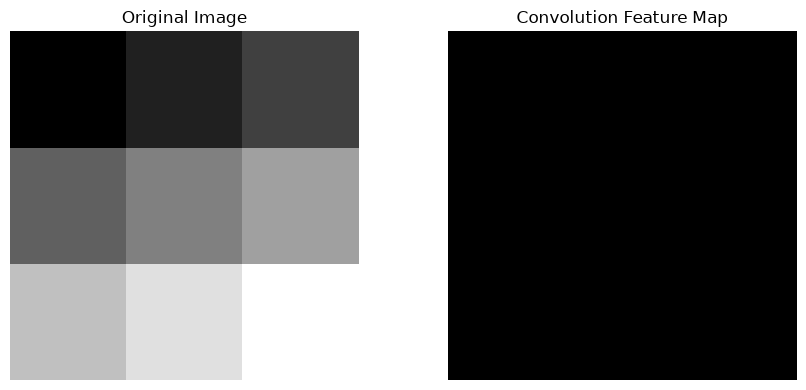

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(feature_map, cmap="gray")
axes[1].set_title("Convolution Feature Map")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## Exercise 2 — Building a Reusable Convolution Function

### Objectives

In this exercise, I will implement a reusable 2D convolution
operation using NumPy.

The function will accept an image and a kernel, calculate
the output dimensions automatically, and generate a feature
map by sliding the kernel across the image.

This implementation uses stride 1 and no padding.

The operation follows the cross-correlation convention used
by PyTorch convolutional layers.

In [1]:
# test image creation

import numpy as np
import matplotlib.pyplot as plt

image = np.array([
    [1, 2, 3, 4, 5],
    [6, 7, 8, 9, 10],
    [11, 12, 13, 14, 15],
    [16, 17, 18, 19, 20],
    [21, 22, 23, 24, 25]
])

kernel = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1]
])

print("Image shape:", image.shape)
print("Kernel shape:", kernel.shape)

Image shape: (5, 5)
Kernel shape: (3, 3)


In [2]:
# output dimensions calculation

image_height, image_width = image.shape
kernel_height, kernel_width = kernel.shape

output_height = image_height - kernel_height + 1
output_width = image_width - kernel_width + 1

print("Output height:", output_height)
print("Output width:", output_width)

Output height: 3
Output width: 3
